# Ampliación del dataset de superficies de la compañera (réplica del método original)

## Objetivo
El dataset original (`topology_dataset.zip`) tiene solo **300 superficies**: 6 géneros (0 a 5), 5 familias por género y 10 muestras por familia. Es muy poco para entrenar una CNN.

En este cuaderno se generan **más superficies con el mismo método con el que venían**, para que las nuevas sean indistinguibles en forma y formato de las originales:

- misma estructura de carpetas: `genus_X/meshes`, `genus_X/pointclouds`, `genus_X/metadata`;
- mismos nombres de archivo: `gX_familyFF_sampleSSS`;
- mismas mallas (70 x 45 = 3150 vértices por unidad), mismo tipo de superficie por género y mismas deformaciones (rotación, escalado anisotrópico y deformación no lineal suave);
- nubes de **3000 puntos** muestreadas sobre la superficie de la malla;
- las 300 superficies originales **no se tocan**; solo se agregan familias nuevas (`family05` en adelante).

## Pasos
1. Cargar librerías y configuración.
2. Descomprimir el original y **revisar cómo está construido** (para copiarlo bien).
3. Definir la geometría: mallas de esfera y de toro.
4. Definir una *familia* (los parámetros base) y una *muestra* (una deformación de esa familia).
5. Generar y guardar las superficies nuevas.
6. Comparar visualmente y con números las originales contra las nuevas.
7. Validar el resultado y empaquetar el ZIP ampliado.

## 1. Librerías y configuración

Se fijan las cantidades a generar. Con `NEW_FAMILIES = 30` se agregan 30 familias nuevas por género y cada familia trae 10 muestras, o sea **300 superficies nuevas por género y 1800 en total**. Todo se genera con semillas fijas, así que el cuaderno es reproducible.

In [1]:
import json  # para leer y escribir los metadatos
import time  # para medir cuánto tarda la generación
import zipfile  # para leer y crear archivos zip
from pathlib import Path  # rutas que sirven en cualquier sistema operativo

import matplotlib.pyplot as plt  # para los gráficos
import numpy as np  # para los arreglos numéricos
import pandas as pd  # para las tablas
from scipy.sparse import coo_matrix  # matriz de adyacencia de las mallas
from scipy.sparse.csgraph import connected_components  # cuenta las piezas separadas de una malla

In [2]:
BASE_DIR = Path.cwd()  # carpeta donde está este cuaderno
ORIGINAL_ZIP = BASE_DIR / "topology_dataset.zip"  # zip original de la compañera
OUTPUT_DIR = BASE_DIR / "topology_dataset_ampliado"  # carpeta del dataset ampliado
DATA_ROOT = OUTPUT_DIR / "topology_dataset"  # misma estructura que el original
ZIP_OUTPUT = BASE_DIR / "topology_dataset_ampliado.zip"  # zip final

GENERA = range(6)  # géneros 0 a 5
ORIGINAL_FAMILIES = 5  # familias que ya traía el original (00 a 04)
NEW_FAMILIES = 30  # familias nuevas por género (05 a 34)
SAMPLES_PER_FAMILY = 10  # muestras por familia, igual que el original
POINTS_PER_CLOUD = 3000  # puntos por nube, igual que el original
N_MAJOR, N_MINOR = 70, 45  # malla de 70 x 45 = 3150 vértices por unidad, igual que el original
SEED_GLOBAL = 20261105  # semilla base de todo el cuaderno
SAVE_MESHES = True  # guarda también los .obj (pon False si solo necesitas las nubes)

if not ORIGINAL_ZIP.exists():  # si el zip no está junto al cuaderno
    raise FileNotFoundError("coloca topology_dataset.zip en la misma carpeta del cuaderno")  # avisa qué falta
print("zip original:", ORIGINAL_ZIP)  # muestra la ruta del zip
print("carpeta de salida:", OUTPUT_DIR)  # muestra la carpeta de salida

zip original: ./topology_dataset.zip
carpeta de salida: ./topology_dataset_ampliado


## 2. Descomprimir y revisar el original

Primero se extrae el zip original a la carpeta de salida (sin los archivos basura de macOS: `__MACOSX` y `.DS_Store`). Esa carpeta será el dataset ampliado: ya trae las 300 originales y encima se agregan las nuevas.

In [3]:
if not DATA_ROOT.exists():  # solo extrae si todavía no está extraído
    with zipfile.ZipFile(ORIGINAL_ZIP, "r") as zf:  # abre el zip original
        members = [n for n in zf.namelist() if n.startswith("topology_dataset/") and "__MACOSX" not in n and ".DS_Store" not in n]  # se queda con los archivos útiles
        zf.extractall(OUTPUT_DIR, members)  # extrae solo esos archivos
print("original disponible en", DATA_ROOT)  # confirma la ruta

original disponible en ./topology_dataset_ampliado/topology_dataset


### Cómo está construido el original

Para copiar bien el método hay que mirar las mallas originales por dentro. Se leen los `.obj` y para cada género se cuenta: vértices, caras, **piezas separadas** de la malla (componentes conexas) y la característica de Euler calculada (V - E + F), junto a la que declara el metadata.

In [4]:
def read_obj(path):  # lee un archivo .obj
    vertices, faces = [], []  # listas vacías de vértices y caras
    with open(path) as f:  # abre el archivo
        for line in f:  # recorre cada línea
            if line.startswith("v "):  # línea de vértice
                vertices.append([float(t) for t in line.split()[1:4]])  # guarda x, y, z
            elif line.startswith("f "):  # línea de cara
                faces.append([int(t.split("/")[0]) - 1 for t in line.split()[1:4]])  # guarda los 3 índices contando desde 0
    return np.array(vertices), np.array(faces)  # devuelve arreglos de numpy


def count_components(n_vertices, faces):  # cuenta las piezas separadas de una malla
    rows = np.r_[faces[:, 0], faces[:, 1], faces[:, 2]]  # un extremo de cada arista
    cols = np.r_[faces[:, 1], faces[:, 2], faces[:, 0]]  # el otro extremo de cada arista
    graph = coo_matrix((np.ones(len(rows)), (rows, cols)), shape=(n_vertices, n_vertices))  # grafo de la malla
    return connected_components(graph, directed=False)[0]  # número de componentes conexas


def euler_characteristic(faces):  # calcula V - E + F
    edges = np.sort(np.r_[faces[:, [0, 1]], faces[:, [1, 2]], faces[:, [2, 0]]], axis=1)  # todas las aristas con extremos ordenados
    n_edges = len(np.unique(edges, axis=0))  # aristas sin repetir
    return len(np.unique(faces)) - n_edges + len(faces)  # vértices - aristas + caras

In [5]:
rows = []  # filas de la tabla
for g in GENERA:  # recorre los géneros
    name = f"g{g}_family00_sample000"  # muestra de ejemplo de cada género
    V, F = read_obj(DATA_ROOT / f"genus_{g}" / "meshes" / f"{name}.obj")  # lee la malla
    meta = json.loads((DATA_ROOT / f"genus_{g}" / "metadata" / f"{name}.json").read_text())  # lee el metadata
    rows.append(dict(  # agrega una fila a la tabla
        genero=g,  # género de la muestra
        tipo=meta["surface_type"],  # tipo de superficie según el metadata
        vertices=len(V),  # vértices de la malla
        caras=len(F),  # caras de la malla
        piezas_separadas=count_components(len(V), F),  # componentes conexas
        chi_calculado=euler_characteristic(F),  # v - e + f calculado de la malla
        chi_en_metadata=meta["euler_characteristic"],  # el que declara el metadata (2 - 2g)
    ))  # agrega la fila
pd.DataFrame(rows)  # muestra la tabla

,genero,tipo,vertices,caras,piezas_separadas,chi_calculado,chi_en_metadata
0,0,sphere_like,3150,6210,1,0,2
1,1,torus,3150,6300,1,0,0
2,2,double_torus_like,6300,12600,2,0,-2
3,3,triple_torus_like,9450,18900,3,0,-4
4,4,quadruple_torus_like,12600,25200,4,0,-6
5,5,quintuple_torus_like,15750,31500,5,0,-8


**Lo que se ve en el original** (y que se replica tal cual en las nuevas):

- Cada *unidad* es una malla de **3150 vértices** (cuadrícula de 70 x 45). Un toro tiene 6300 caras; la esfera tiene 6210 porque no se cierra en un sentido (los polos quedan duplicados, por eso su χ calculado sale 0 aunque sea una esfera).
- Las superficies de género g ≥ 2 son **g toros en cadena** (`double_torus_like`, `triple_torus_like`, ...): la malla tiene exactamente g piezas separadas, cada una con χ = 0. El `euler_characteristic` del metadata (2 − 2g) es el valor *declarado* del género, no el que resulta de la malla.
- Todas tienen rotación, escalado anisotrópico y una deformación no lineal suave (`noise = false`).

> **Nota para el análisis:** como en el original el género g equivale a *g toros*, la CNN puede acertar contando cuántos toros ve, no solo "contando huecos" de una superficie conexa. Se mantiene así porque el pedido es generar más datos igual que los originales, pero conviene tenerlo presente al interpretar las métricas.

## 3. Geometría: mallas de toro y de esfera

- **Toro:** $x=(R+r\cos v)\cos u,\; y=(R+r\cos v)\sin u,\; z=r\sin v$, con $R$ el radio mayor y $r$ el radio del tubo. La cuadrícula es de 70 pasos en $u$ y 45 en $v$, cerrada en los dos sentidos.
- **Esfera (elipsoide):** semiejes $a,b,c$ con 70 pasos de polo a polo y 45 alrededor.
- Las caras son triángulos: cada cuadrado de la cuadrícula se parte en dos.

In [6]:
def grid_faces(n_u, n_v, wrap_u):  # triángulos de una cuadrícula n_u x n_v
    faces = []  # lista de triángulos
    for i in range(n_u if wrap_u else n_u - 1):  # recorre las filas
        i2 = (i + 1) % n_u  # fila siguiente (da la vuelta si wrap_u)
        for j in range(n_v):  # recorre las columnas
            j2 = (j + 1) % n_v  # columna siguiente (siempre da la vuelta)
            a, b, c, d = i * n_v + j, i2 * n_v + j, i2 * n_v + j2, i * n_v + j2  # las 4 esquinas del cuadrado
            faces += [[a, b, c], [a, c, d]]  # el cuadrado se parte en 2 triángulos
    return np.array(faces)  # arreglo (n_caras, 3)


def torus_unit(R, r):  # vértices de un toro
    u = np.linspace(0, 2 * np.pi, N_MAJOR, endpoint=False)[:, None]  # ángulo alrededor del eje del toro
    v = np.linspace(0, 2 * np.pi, N_MINOR, endpoint=False)[None, :]  # ángulo alrededor del tubo
    x = (R + r * np.cos(v)) * np.cos(u)  # coordenada x
    y = (R + r * np.cos(v)) * np.sin(u)  # coordenada y
    z = r * np.sin(v) * np.ones_like(u)  # coordenada z
    return np.stack([x, y, z], -1).reshape(-1, 3)  # lista de 3150 vértices


def sphere_unit(a, b, c):  # vértices de un elipsoide
    u = np.linspace(0, np.pi, N_MAJOR)[:, None]  # de un polo al otro
    v = np.linspace(0, 2 * np.pi, N_MINOR, endpoint=False)[None, :]  # alrededor del eje
    x = a * np.sin(u) * np.cos(v)  # coordenada x
    y = b * np.sin(u) * np.sin(v)  # coordenada y
    z = c * np.cos(u) * np.ones_like(v)  # coordenada z
    return np.stack([x, y, z], -1).reshape(-1, 3)  # lista de 3150 vértices


UNIT_FACES = {"torus": grid_faces(N_MAJOR, N_MINOR, True), "sphere": grid_faces(N_MAJOR, N_MINOR, False)}  # caras de cada unidad
UNIT = N_MAJOR * N_MINOR  # vértices por unidad (3150)


def build_faces(g):  # caras de la superficie de género g
    if g == 0:  # la esfera es una sola unidad
        return UNIT_FACES["sphere"]  # sus caras
    return np.vstack([UNIT_FACES["torus"] + i * UNIT for i in range(g)])  # g toros, cada uno con sus índices desplazados


FACES = {g: build_faces(g) for g in GENERA}  # caras de cada género (no cambian entre muestras)
FACE_TEXT = {g: "\n".join(f"f {a + 1} {b + 1} {c + 1}" for a, b, c in FACES[g]) for g in GENERA}  # caras ya escritas en formato .obj
SURFACE_TYPE = {0: "sphere_like", 1: "torus", 2: "double_torus_like", 3: "triple_torus_like", 4: "quadruple_torus_like", 5: "quintuple_torus_like"}  # nombres que usa el original
print({g: (len(FACES[g]), (UNIT if g == 0 else UNIT * g)) for g in GENERA})  # (caras, vértices) por género

{0: (6210, 3150), 1: (6300, 3150), 2: (12600, 6300), 3: (18900, 9450), 4: (25200, 12600), 5: (31500, 15750)}


## 4. Familias y muestras

El original organiza los datos en dos niveles, y aquí se hace igual:

- **Familia:** los parámetros base de una superficie: radios $R$ y $r$, la separación entre toros de la cadena, la inclinación de cada toro y una pequeña variación de tamaño entre ellos (para la esfera, los tres semiejes). Una familia se fija con una semilla. Los rangos de estos parámetros (en particular que los toros se achican al crecer el género y que la cadena queda casi plana) se **calibraron midiendo las mallas originales**: tamaño de cada toro, distancia entre toros vecinos y valores singulares (largo, ancho y grosor) de la nube.
- **Muestra:** una deformación de esa familia. Cada muestra aplica, en este orden, (1) una **deformación no lineal suave** (suma de 3 ondas senoidales que desplazan los puntos), (2) un **escalado anisotrópico** distinto en cada eje y (3) una **rotación 3D uniforme al azar**.

Las 10 muestras de una misma familia son entonces la misma superficie vista muy deformada de 10 maneras distintas. Esto importa para la CNN: al separar train y test hay que separar por **familia**, no por muestra.

In [7]:
def rot_xyz(ax, ay, az):  # matriz de rotación por ángulos en x, y, z
    cx, sx, cy, sy, cz, sz = np.cos(ax), np.sin(ax), np.cos(ay), np.sin(ay), np.cos(az), np.sin(az)  # senos y cosenos
    Rx = np.array([[1, 0, 0], [0, cx, -sx], [0, sx, cx]])  # giro alrededor de x
    Ry = np.array([[cy, 0, sy], [0, 1, 0], [-sy, 0, cy]])  # giro alrededor de y
    Rz = np.array([[cz, -sz, 0], [sz, cz, 0], [0, 0, 1]])  # giro alrededor de z
    return Rz @ Ry @ Rx  # las junta en una sola matriz


def random_rotation(rng):  # rotación 3D uniforme al azar
    q = rng.normal(size=4)  # cuaternión al azar
    q /= np.linalg.norm(q)  # lo normaliza para que sea una rotación
    w, x, y, z = q  # sus cuatro componentes
    return np.array([  # arma la matriz 3x3
        [1 - 2 * (y * y + z * z), 2 * (x * y - z * w), 2 * (x * z + y * w)],  # primera fila de la matriz
        [2 * (x * y + z * w), 1 - 2 * (x * x + z * z), 2 * (y * z - x * w)],  # segunda fila
        [2 * (x * z - y * w), 2 * (y * z + x * w), 1 - 2 * (x * x + y * y)],  # tercera fila
    ])  # matriz 3x3


SIZE_FACTOR = np.array([1.0, 1.0, 0.78, 0.70, 0.60, 0.59])  # los toros se achican al crecer el género, como en el original


def family_params(g, seed):  # parámetros base de una familia
    rng = np.random.default_rng(seed)  # generador propio de la familia
    p = {  # parámetros comunes
        "R": rng.uniform(0.9, 1.3) * SIZE_FACTOR[g],  # radio mayor del toro
        "r": rng.uniform(0.22, 0.38) * SIZE_FACTOR[g],  # radio del tubo
        "spacing": rng.uniform(2.3, 3.4),  # separación entre toros, en múltiplos de R
    }  # parámetros comunes
    if g == 0:  # esfera
        p["abc"] = rng.uniform(0.8, 1.25, size=3)  # semiejes del elipsoide
    else:  # toros
        p["tilts"] = rng.uniform(-0.3, 0.3, size=(g, 2))  # inclinación de cada toro en radianes (poca: la cadena queda casi plana)
        p["jitter"] = rng.uniform(0.9, 1.1, size=(g, 2))  # variación de R y r entre toros
    return p  # devuelve los parámetros


def base_vertices(g, p):  # vértices de la familia antes de deformar
    if g == 0:  # esfera
        return sphere_unit(*p["abc"])  # un elipsoide
    parts = []  # un bloque de vértices por toro
    for i in range(g):  # recorre los g toros
        V = torus_unit(p["R"] * p["jitter"][i, 0], p["r"] * p["jitter"][i, 1])  # toro con su tamaño
        V = V @ rot_xyz(p["tilts"][i, 0], p["tilts"][i, 1], 0).T  # lo inclina
        V[:, 0] += (i - (g - 1) / 2) * p["spacing"] * p["R"]  # lo coloca en la cadena a lo largo de x
        parts.append(V)  # guarda el toro
    return np.vstack(parts)  # junta todos los toros


def deform(V, rng):  # aplica las tres deformaciones a una muestra
    out = V.copy()  # copia para no modificar la base
    for _ in range(3):  # tres ondas
        w = rng.normal(size=3)  # dirección de la onda
        w *= rng.uniform(0.6, 1.6) / np.linalg.norm(w)  # frecuencia entre 0.6 y 1.6
        d = rng.normal(size=3)  # dirección del desplazamiento
        d /= np.linalg.norm(d)  # la vuelve unitaria
        out += rng.uniform(0.04, 0.16) * np.sin(V @ w + rng.uniform(0, 2 * np.pi))[:, None] * d  # desplaza cada punto según la onda
    S = np.exp(rng.uniform(np.log(0.6), np.log(1.7), size=3))  # escalas anisotrópicas entre 0.6 y 1.7
    out = (out * S) @ random_rotation(rng).T  # escala cada eje y rota al azar
    return out - out.mean(0)  # centra en el origen


def sample_surface(V, F, n, rng):  # n puntos al azar sobre la superficie de la malla
    A, B, C = V[F[:, 0]], V[F[:, 1]], V[F[:, 2]]  # los 3 vértices de cada triángulo
    area = 0.5 * np.linalg.norm(np.cross(B - A, C - A), axis=1)  # área de cada triángulo
    idx = rng.choice(len(F), size=n, p=area / area.sum())  # elige triángulos con probabilidad proporcional al área
    r1, r2 = rng.random(n), rng.random(n)  # dos números al azar por punto
    s = np.sqrt(r1)  # para repartir uniforme dentro del triángulo
    return (1 - s)[:, None] * A[idx] + (s * (1 - r2))[:, None] * B[idx] + (s * r2)[:, None] * C[idx]  # punto con coordenadas baricéntricas

## 5. Guardar y generar

Cada muestra se guarda con la misma estructura del original: la malla `.obj`, la nube `.npy` de 3000 puntos (float64, igual que el original) y el `.json` con los metadatos (mismas claves que el original; se añade `origin` y `seed` para saber que es nueva). Si se interrumpe la ejecución, al volver a correr se saltan las muestras que ya existen.

In [8]:
def sample_name(g, family, sample):  # nombre base de una muestra
    return f"g{g}_family{family:02d}_sample{sample:03d}"  # mismo formato que el original


def save_sample(g, family, sample, V, X, seed):  # guarda malla, nube y metadata
    name = sample_name(g, family, sample)  # nombre de los archivos
    folder = DATA_ROOT / f"genus_{g}"  # carpeta del género
    np.save(folder / "pointclouds" / f"{name}.npy", X)  # guarda la nube de puntos
    if SAVE_MESHES:  # si se piden las mallas
        vertex_text = "\n".join(f"v {x:.6f} {y:.6f} {z:.6f}" for x, y, z in V)  # vértices en formato .obj
        (folder / "meshes" / f"{name}.obj").write_text(vertex_text + "\n" + FACE_TEXT[g] + "\n")  # vértices y caras
    meta = {  # metadata de la muestra
        "genus": g,  # género
        "euler_characteristic": 2 - 2 * g,  # igual que el original: el valor declarado del género
        "family": family,  # número de familia
        "sample": sample,  # número de muestra
        "surface_type": SURFACE_TYPE[g],  # tipo de superficie
        "n_points": len(X),  # puntos de la nube
        "mesh_vertices": len(V),  # vértices de la malla
        "mesh_faces": len(FACES[g]),  # caras de la malla
        "deformations": {"rotation": True, "anisotropic_scaling": True, "smooth_nonlinear": True, "noise": False},  # mismas deformaciones
        "origin": "ampliacion",  # marca las muestras nuevas
        "seed": seed,  # semilla de la muestra
    }  # metadata de la muestra
    (folder / "metadata" / f"{name}.json").write_text(json.dumps(meta, indent=4))  # guarda el metadata
    return meta  # devuelve el metadata

In [9]:
start = time.time()  # hora de inicio
new_meta = []  # metadatos de las muestras nuevas
for g in GENERA:  # recorre los géneros
    for c in ("meshes", "pointclouds", "metadata"):  # las tres subcarpetas
        (DATA_ROOT / f"genus_{g}" / c).mkdir(parents=True, exist_ok=True)  # las crea si faltan
    for family in range(ORIGINAL_FAMILIES, ORIGINAL_FAMILIES + NEW_FAMILIES):  # familias nuevas 05 a 34
        params = family_params(g, SEED_GLOBAL + g * 1000 + family)  # parámetros base de la familia
        V0 = base_vertices(g, params)  # vértices sin deformar
        for sample in range(SAMPLES_PER_FAMILY):  # 10 muestras por familia
            name = sample_name(g, family, sample)  # nombre de la muestra
            folder = DATA_ROOT / f"genus_{g}"  # carpeta del género
            json_path = folder / "metadata" / f"{name}.json"  # ruta del metadata
            done = json_path.exists() and (folder / "pointclouds" / f"{name}.npy").exists() and (not SAVE_MESHES or (folder / "meshes" / f"{name}.obj").exists())  # ¿ya existe todo?
            if done:  # si ya se generó en una ejecución anterior
                new_meta.append(json.loads(json_path.read_text()))  # solo lee su metadata
                continue  # pasa a la siguiente
            seed = SEED_GLOBAL + g * 100000 + family * 100 + sample  # semilla de la muestra
            rng = np.random.default_rng(seed)  # generador de la muestra
            V = deform(V0, rng)  # deforma la familia
            X = sample_surface(V, FACES[g], POINTS_PER_CLOUD, rng)  # muestrea la nube de 3000 puntos
            new_meta.append(save_sample(g, family, sample, V, X, seed))  # guarda y recuerda el metadata
    print(f"género {g}: {sum(m['genus'] == g for m in new_meta)} muestras nuevas, {(time.time() - start) / 60:.1f} min")  # progreso
new_df = pd.DataFrame(new_meta)  # tabla con las muestras nuevas
print("total de muestras nuevas:", len(new_df))  # total

género 0: 300 muestras nuevas, 0.0 min


género 1: 300 muestras nuevas, 0.1 min


género 2: 300 muestras nuevas, 0.2 min


género 3: 300 muestras nuevas, 0.2 min


género 4: 300 muestras nuevas, 0.4 min


género 5: 300 muestras nuevas, 0.5 min
total de muestras nuevas: 1800


## 6. Comparación: originales contra nuevas

Se grafica, para cada género, dos superficies originales (columnas 1 y 2) y dos nuevas (columnas 3 y 4), con el mismo estilo de colores por altura que se usó para visualizar el original. Las nuevas deben verse como parientes de las originales.

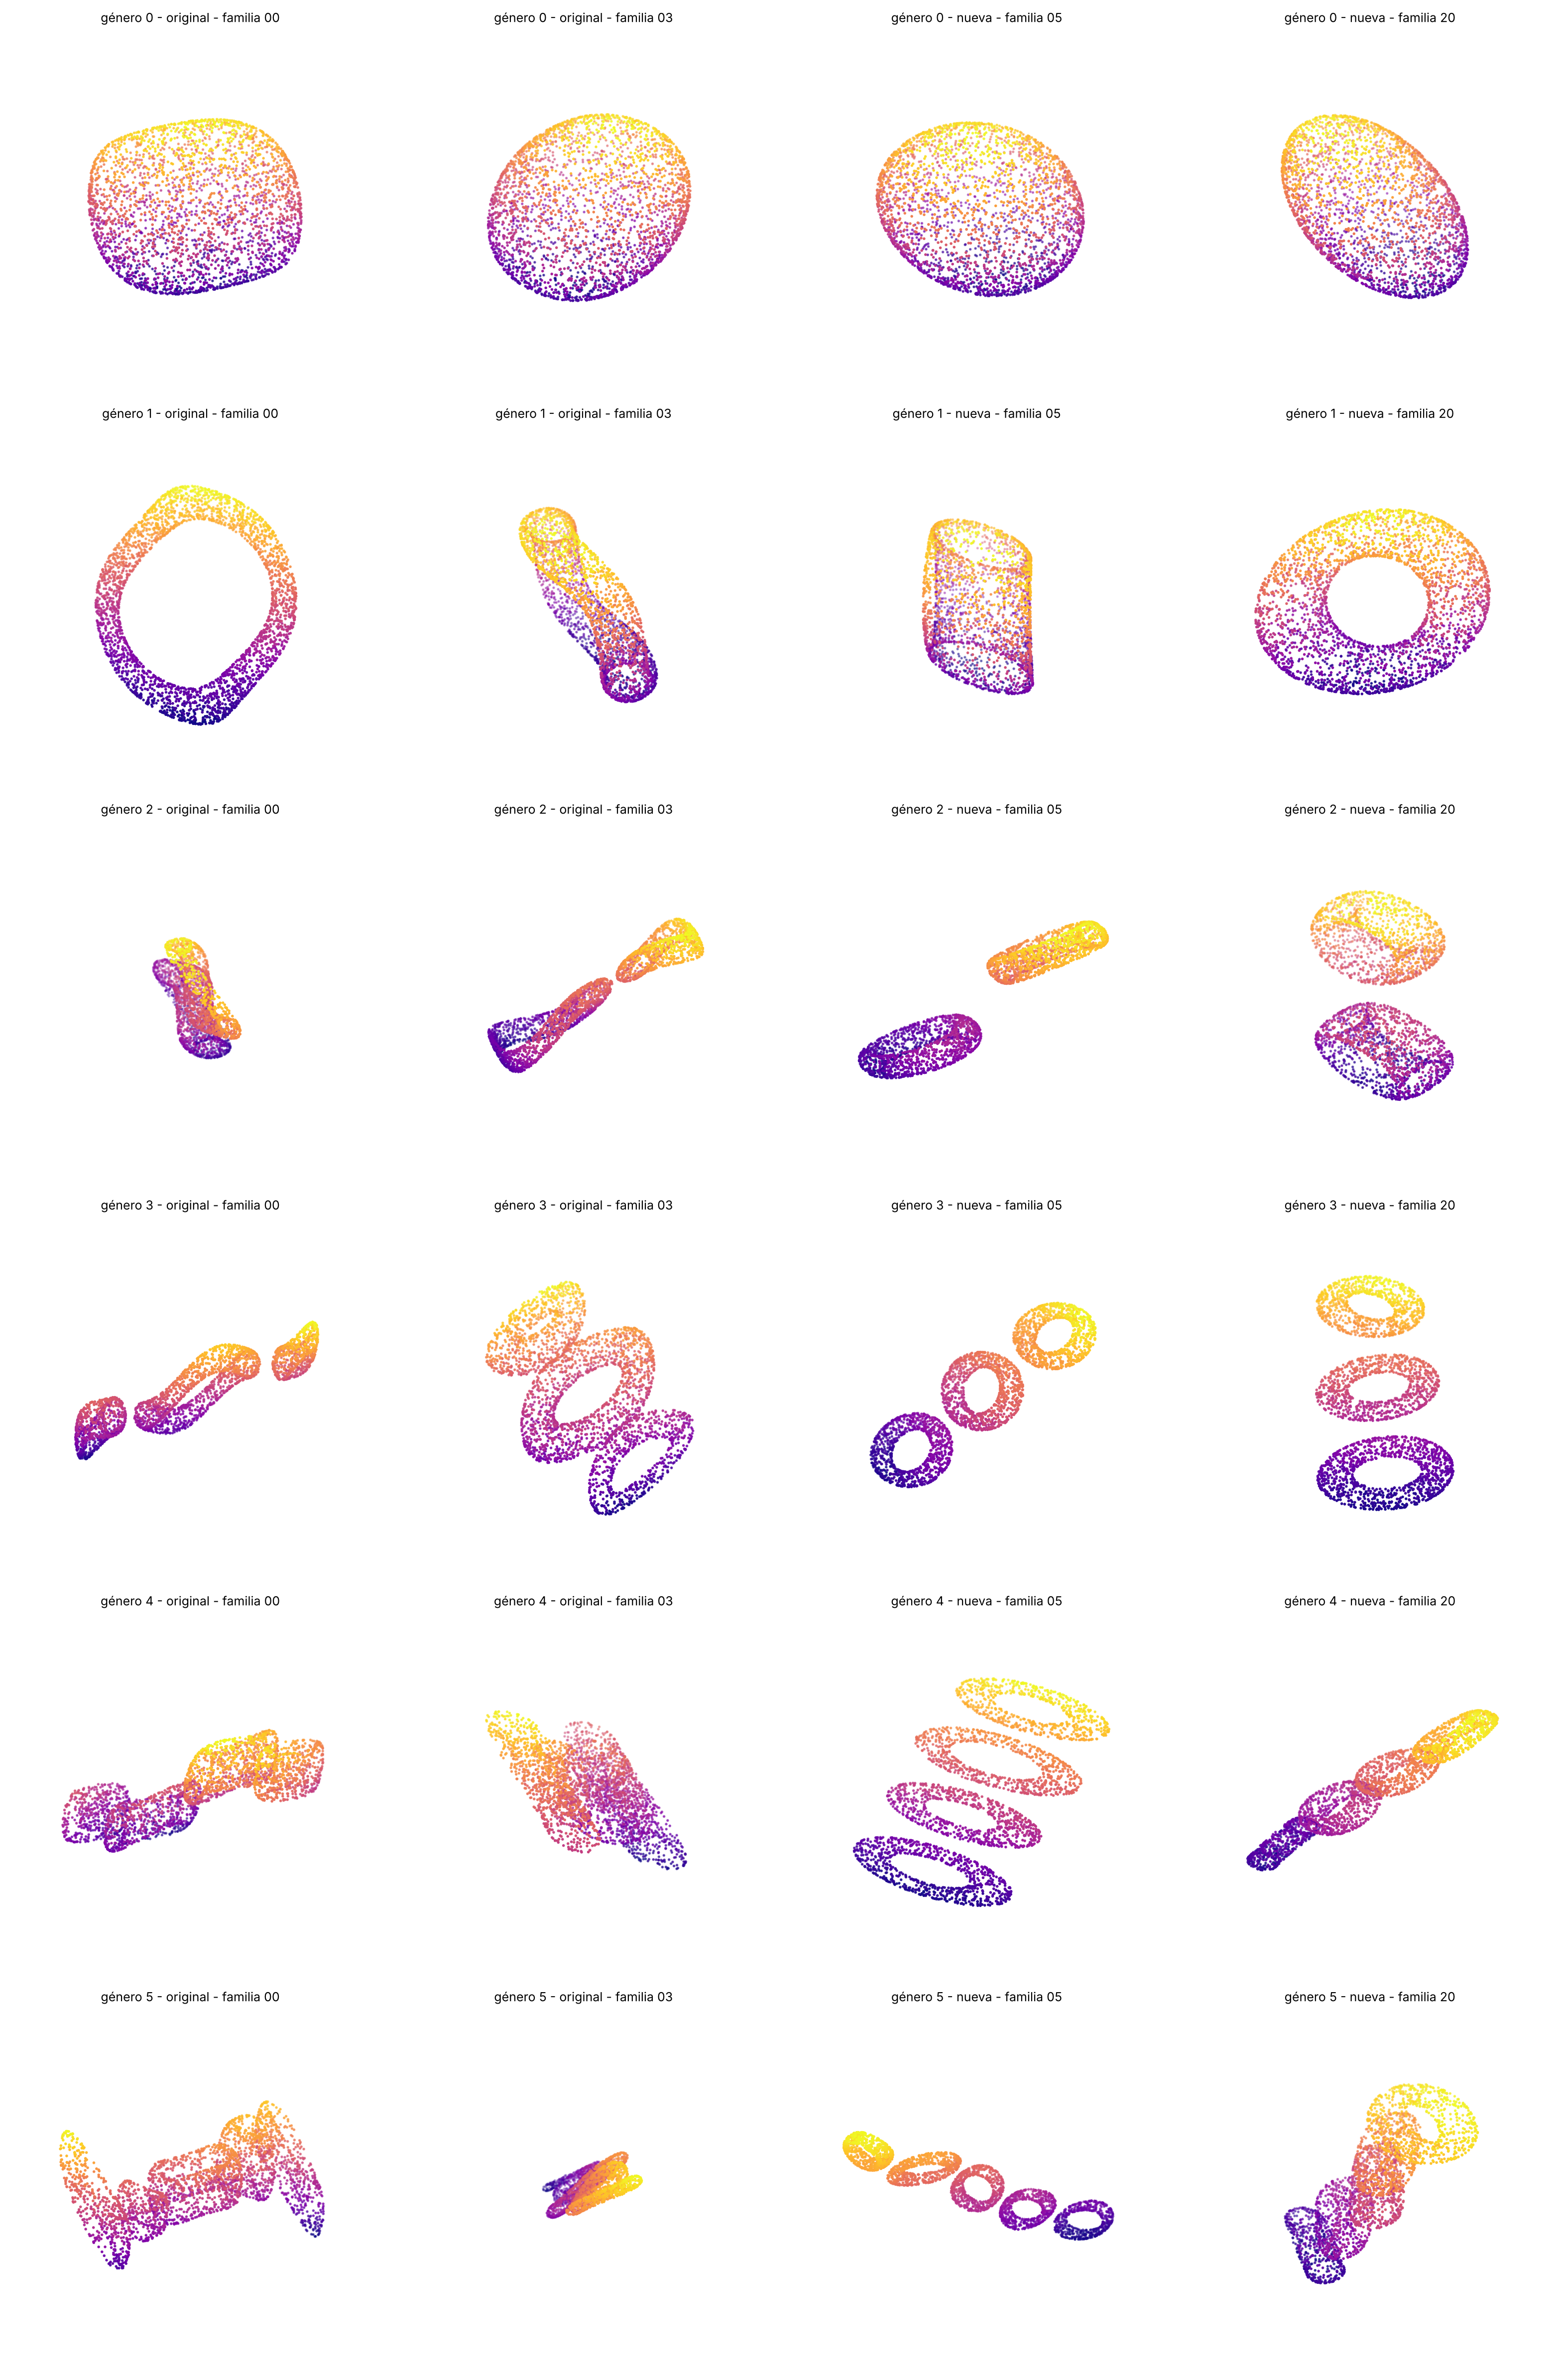

In [10]:
def load_cloud(g, family, sample):  # carga una nube de puntos
    return np.load(DATA_ROOT / f"genus_{g}" / "pointclouds" / f"{sample_name(g, family, sample)}.npy")  # lee el .npy


picks = [(0, 0, "original"), (3, 5, "original"), (5, 0, "nueva"), (20, 5, "nueva")]  # (familia, muestra, origen) de cada columna
fig = plt.figure(figsize=(16, 24))  # figura grande
for g in GENERA:  # una fila por género
    for k, (family, sample, origin) in enumerate(picks):  # cuatro columnas
        X = load_cloud(g, family, sample)  # nube de la muestra
        ax = fig.add_subplot(6, 4, g * 4 + k + 1, projection="3d")  # panel 3d
        ax.scatter(X[:, 0], X[:, 1], X[:, 2], s=1, c=X[:, 2], cmap="plasma")  # puntos coloreados por altura
        ax.set_title(f"género {g} - {origin} - familia {family:02d}", fontsize=9)  # título
        ax.set_axis_off()  # sin ejes
plt.tight_layout()  # ajusta los espacios
plt.show()  # muestra la figura

### Comparación numérica

Además de mirar las figuras, se compara el tamaño de las nubes. Para cada nube se calculan las tres dimensiones de su caja envolvente (ordenadas de mayor a menor) y se promedian por género y por origen. Si el método está bien replicado, las originales y las nuevas deben tener tamaños del mismo orden y la misma tendencia con el género (más toros, más largo).

In [11]:
rows = []  # filas de la tabla
for g in GENERA:  # recorre los géneros
    for path in sorted((DATA_ROOT / f"genus_{g}" / "pointclouds").glob("*.npy")):  # todas las nubes del género
        family = int(path.stem.split("_")[1].replace("family", ""))  # número de familia desde el nombre
        X = np.load(path)  # carga la nube
        ext = np.sort(X.max(0) - X.min(0))[::-1]  # dimensiones de la caja, de mayor a menor
        rows.append(dict(genero=g, origen="original" if family < ORIGINAL_FAMILIES else "nueva", n_puntos=len(X), largo=ext[0], medio=ext[1], corto=ext[2]))  # resume la nube
stats = pd.DataFrame(rows)  # tabla de todas las nubes
stats.groupby(["genero", "origen"]).agg(muestras=("largo", "size"), n_puntos=("n_puntos", "first"), largo=("largo", "mean"), medio=("medio", "mean"), corto=("corto", "mean")).round(2)  # resumen por género y origen

muestras  n_puntos  largo  medio  corto
genero origen                                           
0      nueva          300      3000   2.55   2.17   1.82
       original        50      3000   2.75   2.32   2.01
1      nueva          300      3000   3.11   2.52   1.76
       original        50      3000   3.22   2.62   1.74
2      nueva          300      3000   4.27   3.18   2.10
       original        50      3000   4.14   3.28   2.25
3      nueva          300      3000   5.55   3.87   2.45
       original        50      3000   5.24   3.83   2.66
4      nueva          300      3000   6.69   4.27   2.61
       original        50      3000   6.00   4.12   2.63
5      nueva          300      3000   8.17   5.10   2.97
       original        50      3000   7.28   4.62   2.64

## 7. Validación y conteo final

Se comprueba que:

- cada género tiene 50 muestras originales y 300 nuevas (35 familias x 10 muestras);
- todas las nubes tienen 3000 puntos y valores finitos;
- en una muestra de mallas nuevas (10 por género) el número de piezas separadas es igual a g (1 para g = 0), y los vértices y caras coinciden con los del original.

In [12]:
counts = stats.groupby(["genero", "origen"]).size().unstack()  # muestras por género y origen
counts["total"] = counts.sum(axis=1)  # total por género
display(counts)  # muestra la tabla
assert (counts["original"] == 50).all()  # 50 originales por género
assert (counts["nueva"] == NEW_FAMILIES * SAMPLES_PER_FAMILY).all()  # 300 nuevas por género
assert (stats["n_puntos"] == POINTS_PER_CLOUD).all()  # todas con 3000 puntos

check_rng = np.random.default_rng(0)  # generador para elegir las mallas a revisar
check_rows = []  # filas de la revisión
for g in GENERA:  # recorre los géneros
    if not SAVE_MESHES:  # si no se guardaron mallas
        break  # no hay nada que revisar
    for family, sample in zip(check_rng.integers(ORIGINAL_FAMILIES, ORIGINAL_FAMILIES + NEW_FAMILIES, 10), check_rng.integers(0, SAMPLES_PER_FAMILY, 10)):  # 10 mallas nuevas al azar
        V, F = read_obj(DATA_ROOT / f"genus_{g}" / "meshes" / f"{sample_name(g, int(family), int(sample))}.obj")  # lee la malla
        expected_pieces = max(g, 1)  # piezas esperadas
        check_rows.append(dict(genero=g, ok_piezas=count_components(len(V), F) == expected_pieces, ok_vertices=len(V) == UNIT * expected_pieces, ok_caras=len(F) == len(FACES[g]), ok_finito=bool(np.isfinite(V).all())))  # revisa la malla
if check_rows:  # si hubo mallas para revisar
    check = pd.DataFrame(check_rows)  # tabla de la revisión
    display(check.groupby("genero").all())  # todo debe dar True
    assert check.drop(columns="genero").all().all()  # falla si algo no coincide

clouds_ok = all(np.isfinite(np.load(p)).all() for p in (DATA_ROOT / "genus_5" / "pointclouds").glob("*.npy"))  # nubes del género 5 sin NaN
print("nubes finitas (género 5):", clouds_ok)  # confirma
print("total de superficies en el dataset ampliado:", int(counts["total"].sum()))  # total final

origen,nueva,original,total
genero,,,
0,300,50,350
1,300,50,350
2,300,50,350
3,300,50,350
4,300,50,350
5,300,50,350


,ok_piezas,ok_vertices,ok_caras,ok_finito
genero,,,,
0,True,True,True,True
1,True,True,True,True
2,True,True,True,True
3,True,True,True,True
4,True,True,True,True
5,True,True,True,True


nubes finitas (género 5): True
total de superficies en el dataset ampliado: 2100


## 8. Exportación del dataset ampliado

Se escribe un `README` y se empaqueta todo en `topology_dataset_ampliado.zip`, con la misma estructura del zip original (carpeta `topology_dataset/` con `genus_0` a `genus_5`). Ese zip (o la carpeta `topology_dataset_ampliado/`) es lo que usa el cuaderno de la CNN.

In [13]:
readme = "\n".join([  # texto del readme
    "# Dataset de superficies ampliado",  # título
    "",  # línea vacía
    f"- Muestras originales: {int((counts['original']).sum())} (familias 00 a 04, sin modificar)",  # originales
    f"- Muestras nuevas: {int(counts['nueva'].sum())} (familias {ORIGINAL_FAMILIES:02d} a {ORIGINAL_FAMILIES + NEW_FAMILIES - 1:02d}, {SAMPLES_PER_FAMILY} muestras por familia)",  # nuevas
    "- Géneros: 0 a 5, mismas carpetas y nombres que el original",  # estructura
    f"- Puntos por nube: {POINTS_PER_CLOUD}",  # puntos
    "- Método: g toros en cadena (esfera para g = 0) con rotación, escalado anisotrópico y deformación no lineal suave",  # método
    "- Semillas fijas: el cuaderno regenera exactamente las mismas muestras",  # reproducibilidad
])  # texto del README
(OUTPUT_DIR / "README_ampliacion.md").write_text(readme)  # lo guarda

if not ZIP_OUTPUT.exists():  # si el zip no existe todavía
    with zipfile.ZipFile(ZIP_OUTPUT, "w", compression=zipfile.ZIP_DEFLATED, compresslevel=1) as zf:  # crea el zip
        for path in sorted(DATA_ROOT.rglob("*")):  # recorre todos los archivos
            if path.is_file():  # solo archivos, no carpetas
                zf.write(path, path.relative_to(OUTPUT_DIR).as_posix())  # los agrega con ruta relativa
        zf.write(OUTPUT_DIR / "README_ampliacion.md", "README_ampliacion.md")  # agrega el README
print("zip:", ZIP_OUTPUT.name, "-", round(ZIP_OUTPUT.stat().st_size / 1024**2, 1), "MB")  # tamaño del zip

zip: topology_dataset_ampliado.zip - 532.6 MB
